# LegumAmies - HESTIA sustainability indicators (Milestone 2)

**Objective.** Enrich LegumAmies with *sustainability* context for French
legumes - greenhouse-gas emissions, land use and water impacts - using the
official [HESTIA](https://www.hestia.earth) (University of Oxford) Data API.
This is **complementary** to the AROME/ECMWF climate-risk MVP; it does not
replace it.

**What this notebook is and is not.**
- It retrieves *real, published, aggregated* environmental impact data.
- HESTIA aggregated nodes are **national/regional estimates over a period**
  (e.g. France, 2010-2026), **not** measurements of an individual field.
- Nothing is fabricated: crops without published French coverage are reported
  as missing, not invented.

**Reproducibility.** Runs in Kiro/Ubuntu, Google Colab and AWS Jupyter via
repository-relative paths; all logic lives in `src/sustainability/hestia.py`
and is called from here.

## 0. Environment bootstrap
**Objective:** make `src` importable regardless of host. **Method:** walk up
to the repo root (the folder containing `src/` and `requirements.txt`); on
Colab, clone the repository if needed. **Output:** `REPO_ROOT` on `sys.path`.

In [1]:
import sys, subprocess
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'src').is_dir() and (p / 'requirements.txt').exists():
            return p
    return start

try:
    HERE = Path(__file__).resolve().parent
except NameError:
    HERE = Path.cwd()
REPO_ROOT = find_repo_root(HERE)
if not (REPO_ROOT / 'src').is_dir() and 'google.colab' in sys.modules:
    subprocess.run(['git', 'clone', 'https://github.com/Eric-Kambire/LegumAmies'], check=False)
    REPO_ROOT = Path('LegumAmies').resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print('Repo root:', REPO_ROOT)

Repo root: /home/ubuntu/Downloads/LegumAmies


## 1. Choose the data release (the `X-Data-Version` header)
**Objective:** pick a reproducible, *public* HESTIA release.

**Methodology / rules (from the HESTIA docs):**
- Every request must send `X-Data-Version` set to a release **date**
  (`YYYY-MM-DD`), never a version label like `v1.2`.
- A release is embargoed for its first **182 days**; asking for an embargoed
  release returns HTTP 401.
- We therefore select the newest release that is both `enabled` and older
  than 182 days. Pin it deliberately so results stay reproducible.

**Inputs:** `GET /settings/dataReleases`. **Output:** the chosen release date.

In [2]:
from src.sustainability import hestia
releases = hestia.get_data_releases()
release_date, release_name = hestia.select_public_release(releases)
print('Available releases :', releases)
print('Chosen release     :', release_date, '(', release_name, ')')

Available releases : {'2025-05-01': {'name': 'v1.0', 'enabled': True}, '2026-03-10': {'name': 'v1.1', 'enabled': True}, '2026-04-30': {'name': 'v1.2', 'enabled': True}}
Chosen release     : 2026-04-30 ( v1.2 )


## 2. Which French legumes does HESTIA actually cover?
**Objective:** establish *honest coverage* before extracting any numbers.

**Methodology:** search the chosen release for validated, aggregated
`ImpactAssessment` nodes in France (`aggregated=true` **and**
`aggregatedDataValidated=true`), then match each node's product against our
seven target legumes (HESTIA names faba/field bean *Broad bean* and dry bean
*Common bean*).

**Output:** a coverage table. **Interpretation:** crops marked `covered=False`
simply have no published French aggregate in this release - a real gap, not a
modelling choice.

In [3]:
import pandas as pd
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 180)

sustainability_df, coverage_df, meta = hestia.build_country_legume_sustainability(
    country='France', release=release_date, save=True)
coverage_df

,country,crop,hestia_product_id,hestia_product_name,covered,ia_id,note
0,France,soybean,soybeanSeedWhole,"Soybean, seed (whole)",False,NaN,no validated aggregated IA for France in relea...
1,France,fava_bean,broadBeanSeedWhole,"Broad bean, seed (whole)",False,NaN,no validated aggregated IA for France in relea...
2,France,chickpea,chickpeaSeedWhole,"Chickpea, seed (whole)",False,NaN,no validated aggregated IA for France in relea...
3,France,pea,peaSeedWhole,"Pea, seed (whole)",True,peaSeedWhole-france-2010-2026-20260418,validated aggregated IA found
4,France,lentil,lentilSeedWhole,"Lentil, seed (whole)",False,NaN,no validated aggregated IA for France in relea...
5,France,lupin,lupinSeedWhole,"Lupin, seed (whole)",False,NaN,no validated aggregated IA for France in relea...
6,France,dry_bean,commonBeanSeedWhole,"Common bean, seed (whole)",False,NaN,no validated aggregated IA for France in relea...


### 2.1 Coverage summary
**Interpretation:** the covered vs missing split, straight from the API.

In [4]:
print('Covered :', meta['crops_covered'])
print('Missing :', meta['crops_missing'])
print('Release :', meta['x_data_version_header'], '|', meta['release_name'])
print('Licence :', meta['licence'])

Covered : ['pea']
Missing : ['chickpea', 'dry_bean', 'fava_bean', 'lentil', 'lupin', 'soybean']
Release : 2026-04-30 | v1.2
Licence : ['CC-BY']


## 3. Sustainability indicators for covered crops
**Objective:** present the retrieved indicators with full provenance.

**Indicators (per functional unit = 1 kg of product):**
- `ghg_emissions` - GWP100 (kg CO2 eq), method IPCC (2021)
- `land_use` - land occupation during cycle (m2*year)
- `water_use` - freshwater withdrawals during cycle (L)
- `water_scarcity` - scarcity-weighted water use (L eq)
- `land_quality` - soil quality index, total land-use effects (points)

**Calculation:** HESTIA stores each aggregated indicator as a bootstrap
`distribution` array. We report the **mean** as the headline value and the
**sd / min / max / n** so the spread is explicit. **Output:** the long table
`hestia_legume_sustainability.csv`.

In [5]:
cols = ['crop','indicator_category','indicator_label','value_mean','value_sd',
        'value_min','value_max','n_samples','unit','method_model','functional_unit']
sustainability_df[cols] if len(sustainability_df) else 'No covered crops in this release.'

,crop,indicator_category,indicator_label,value_mean,value_sd,value_min,value_max,n_samples,unit,method_model,functional_unit
0,pea,ghg_emissions,Global warming potential (GWP100),0.275,0.059144,0.13,0.493,1000,kg CO2 eq,IPCC (2021),1 kg
1,pea,land_use,"Land occupation, during cycle",3.010,0.185133,2.38,3.090,1000,m2*year,HESTIA,1 kg
2,pea,water_use,"Freshwater withdrawals, during cycle",34.700,44.411818,16.60,214.000,1000,L,Poore & Nemecek (2018),1 kg
3,pea,water_scarcity,Scarcity-weighted water use,441.000,318.844940,159.00,1846.000,1000,L eq,Environmental Footprint v3.1,1 kg
4,pea,land_quality,"Soil quality index, total land-use effects",264.000,16.187269,209.00,271.000,1000,points,Environmental Footprint v3.1,1 kg


### 3.1 Provenance (where each number comes from)
**Why it matters:** every value must be traceable. Below: the HESTIA node id,
release, bibliographic source, licence, aggregation quality score and the
period the aggregate spans.

In [6]:
prov_cols = ['crop','ia_id','release_date','release_name','source_citation',
             'licence','aggregated_quality_score','aggregated_quality_score_max',
             'period_start','period_end','data_kind']
sustainability_df[prov_cols].drop_duplicates() if len(sustainability_df) else 'n/a'

,crop,ia_id,release_date,release_name,source_citation,licence,aggregated_quality_score,aggregated_quality_score_max,period_start,period_end,data_kind
0,pea,peaSeedWhole-france-2010-2026-20260418,2026-04-30,v1.2,HESTIA Team (2023),CC-BY,2,4,2010,2026,hestia_aggregated_national_estimate


### 3.2 GHG emissions with uncertainty (chart)
**Objective:** visualise the GWP100 mean and its distribution spread.
**Interpretation:** the error bar is the sd across the aggregated bootstrap
samples - it is uncertainty in the *national aggregate*, not field-level error.

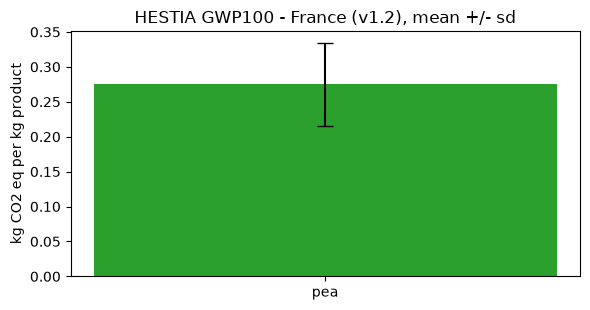

In [7]:
import matplotlib.pyplot as plt
ghg = sustainability_df[sustainability_df['indicator_category'] == 'ghg_emissions']
if len(ghg):
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.bar(ghg['crop'], ghg['value_mean'], yerr=ghg['value_sd'].fillna(0),
           capsize=6, color='tab:green')
    ax.set_ylabel('kg CO2 eq per kg product')
    ax.set_title(f"HESTIA GWP100 - France ({release_name}), mean +/- sd")
    plt.tight_layout(); plt.show()
else:
    print('No GHG rows to plot for this release.')

## 4. How this connects to the climate MVP (and how it must NOT be used)
**Objective:** state the integration boundary explicitly.

- The climate pipeline (AROME + AIFS) drives operational, field-and-day
  decisions: flowering risk and harvest timing.
- HESTIA adds *strategic sustainability context* per crop (GHG/land/water).
- **Do not** attach a HESTIA national aggregate to a specific field as if it
  were measured there. In the product it should be shown as a crop-level
  reference with its release, source and licence visible.
- Current French coverage is **pea only**; the UI must degrade gracefully for
  crops with no HESTIA data (empty state), never invent a value.

In [8]:
from src import config
import os
print('Processed HESTIA outputs:')
for f in ['hestia_legume_sustainability.csv','hestia_coverage.csv','hestia_metadata.json']:
    p = config.PROCESSED_DIR / f
    print('  -', p.relative_to(config.ROOT), '(exists:', p.exists(), ')')

Processed HESTIA outputs:
  - data/processed/hestia_legume_sustainability.csv (exists: True )
  - data/processed/hestia_coverage.csv (exists: True )
  - data/processed/hestia_metadata.json (exists: True )


## 5. Limitations
- **Coverage.** Only validated French aggregates are used; in release `v1.2` that is **pea** alone. The other six legumes are genuinely absent for France and are reported as missing.
- **Not field measurements.** Values are national/regional aggregates over 2010-2026; they describe a crop in a country, not this farmer's plot.
- **Uncertainty.** Headline values are distribution means; the sd/min/max show wide spread for some water indicators (right-skewed).
- **Release-scoped ids.** Aggregation ids are valid only within their release; changing `X-Data-Version` changes ids and numbers.
- **Licence.** HESTIA source licence recorded per row (here `CC-BY`); attribute HESTIA when displaying.
- **No modelling on top.** We do not combine HESTIA with weather to predict damage or yield; that would require validated agronomic models.